# Step 5: Gate and evaluation (blend Model 1 and Model 2)

Final score for every candidate: **score = w · P1 + (1 − w) · P2**, where `w` is the weight on Model 1.

1. **P1 and P2:** both models' scores as purchase probabilities (Platt scaling on val2, done in each model's step 4 notebook).
2. **Fit the gate on val2** and compare:
   - **Gate A** (as in MOHR, Wang et al. 2024): one `w` for everyone, chosen by NDCG@10, with and without the short-history rule (`w = 1` for at most 10 past actions).
   - **Gate C** (learned gate, inputs from `step2_gate_features.ipynb`): `w` depends on three facts about the user, in three versions that show why it wins or loses.
3. **Evaluate on train, val2 and test:** the chosen gate, with Model 1 alone and Model 2 alone as comparison rows. Test is the honest result.

**Final gate:** Gate A, `w = 0.70` (see "Final gate" below). `w` is chosen on val2, so val2 numbers are optimistic.

**Inputs**

| Folder | Files | Used for |
|---|---|---|
| `step1/` | `train_sampled`, `val2`, `test` `.parquet` | product at each position, history length |
| `step4_model1/` | `model1_scores_{train,val2,test}.parquet`, `calibration.json` | P1 |
| `step4_model2/` | `model2_predictions_{train,val2,test}.parquet`, `calibration.json` | P2 |
| `step2_gate/` | `gate_val.parquet`, `gate_test.parquet` | Gate C's user features |

**Outputs** (in `step5/`)
- Gate: `gate_config.json`, `gate_val2_results.csv`, `gate_weight_curve_val2.csv`
- Evaluation: `evaluation_overall.csv`, `evaluation_by_history.csv`, `evaluation_test_paired_diff.csv`

**Run order:** after both step 4 notebooks and `step2_gate_features.ipynb`. CPU only, a few minutes. Restart, then run all.

In [1]:
# Setup: Colab mounts Drive; locally, Google Drive for desktop. GRP8_PROJECT overrides both.
import os
from pathlib import Path

if "GRP8_PROJECT" in os.environ:
    PROJECT = Path(os.environ["GRP8_PROJECT"])
else:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT = Path("/content/drive/MyDrive/Grp8Submission/pipeline_data")
    except ImportError:
        PROJECT = sorted(Path.home().glob("Library/CloudStorage/GoogleDrive-*/My Drive/Grp8Submission"))[0]
print("PROJECT =", PROJECT)

Mounted at /content/drive
PROJECT = /content/drive/MyDrive/Grp8Submission/pipeline_data


In [2]:
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy.special import expit

DATA = PROJECT / "step1"                       # step 1 outputs
M1_DIR = PROJECT / "step4_model1"              # Model 1 scores and calibration
M2_DIR = PROJECT / "step4_model2"              # Model 2 predictions and calibration
GATE_DIR = PROJECT / "step2_gate"              # from step2_gate_features.ipynb
OUT_DIR = PROJECT / "step5"                    # this notebook's outputs
OUT_DIR.mkdir(parents=True, exist_ok=True)

W_GRID = np.round(np.arange(0, 1.0001, 0.05), 2)  # w = weight on Model 1
HISTORY_BUCKETS = [10, 29, 78, 188]               # group edges (past actions); first group = short history
                                                  # (10 = train 10th percentile, same as step2_gate_features)

## Metric code
Copied from `step4_model1_lightgbm.ipynb` (section 2), the same code as the feature, ablation and DIN notebooks, so every model in the report is scored identically. The functions this notebook does not use (`summarize`, `seed_avg`) are left out.

In [3]:
METRICS = ["ndcg@10", "hit@10", "hit@1", "mrr"]


def _gains(label, relevance):
    label = np.asarray(label)
    if relevance == "purchase":
        return (label == 3).astype(np.float64)
    if relevance == "graded":
        return (2.0 ** label - 1.0).astype(np.float64)
    raise ValueError("relevance must be 'purchase' or 'graded'")


def _group_layout(sorted_slates):
    # start index of each slate block in an array sorted by slate, and the 1-based rank inside it
    n = len(sorted_slates)
    start = np.r_[0, np.flatnonzero(sorted_slates[1:] != sorted_slates[:-1]) + 1]
    size = np.diff(np.r_[start, n])
    rank = np.arange(n) - np.repeat(start, size) + 1
    return start, rank


def per_slate_metrics(df, score_col, k=10, relevance="purchase", higher_is_better=True, n_tiebreaks=5, seed=0):
    # one row per slate that has a relevant item, with ndcg@k, hit@k, hit@1, mrr
    slate = df["slate_id"].to_numpy()
    gain = _gains(df["label"].to_numpy(), relevance)
    has_rel = pd.Series(gain > 0).groupby(slate).transform("any").to_numpy()
    slate, gain = slate[has_rel], gain[has_rel]
    score = df[score_col].to_numpy(dtype=np.float64)[has_rel]
    if len(slate) == 0:
        raise ValueError("no slates with a relevant item")
    key = score if higher_is_better else -score
    key = np.where(np.isnan(key), -np.inf, key)
    ideal_order = np.lexsort((-gain, slate))
    start, rank = _group_layout(slate[ideal_order])
    disc = np.where(rank <= k, 1.0 / np.log2(rank + 1), 0.0)
    idcg = np.add.reduceat(gain[ideal_order] * disc, start)
    rng = np.random.default_rng(seed)
    acc = {m: np.zeros(len(start)) for m in METRICS}
    for _ in range(n_tiebreaks):
        tie = rng.random(len(slate))
        order = np.lexsort((tie, -key, slate))
        g = gain[order]
        rel = g > 0
        acc["ndcg@10"] += np.add.reduceat(g * disc, start) / idcg
        acc["hit@10"] += np.add.reduceat((rel & (rank <= k)).astype(float), start) > 0
        acc["hit@1"] += np.add.reduceat((rel & (rank == 1)).astype(float), start) > 0
        first = np.minimum.reduceat(np.where(rel, rank, np.inf), start)
        acc["mrr"] += 1.0 / first
    out = pd.DataFrame({m: v / n_tiebreaks for m, v in acc.items()})
    out = out.rename(columns={"ndcg@10": f"ndcg@{k}", "hit@10": f"hit@{k}"})
    out.insert(0, "slate_id", slate[ideal_order][start])
    return out


def paired_diff(a, b, col="ndcg@10", n_boot=2000, seed=0):
    # mean of a - b over the same slates, with a 95% bootstrap interval
    assert (a["slate_id"].to_numpy() == b["slate_id"].to_numpy()).all(), "slates not aligned"
    d = a[col].to_numpy() - b[col].to_numpy()
    rng = np.random.default_rng(seed)
    boot = d[rng.integers(0, len(d), size=(n_boot, len(d)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"diff": d.mean(), "ci_low": lo, "ci_high": hi}


def self_test():
    # hand-checkable toy slates (same cases as the feature notebook)
    d = pd.DataFrame({"slate_id": [1, 1, 1, 2, 2, 3, 3], "label": [0, 3, 0, 3, 1, 0, 1],
                      "s": [0.9, 0.5, 0.1, 0.8, 0.2, 0.5, 0.4]})
    ps = per_slate_metrics(d, "s").set_index("slate_id")
    assert list(ps.index) == [1, 2]
    assert np.isclose(ps.loc[1, "ndcg@10"], 1 / np.log2(3)) and ps.loc[1, "mrr"] == 0.5 and ps.loc[1, "hit@1"] == 0
    assert (ps.loc[2] == 1).all()
    d2 = d.assign(s=[0.9, np.nan, 0.1, 0.8, 0.2, 0.5, 0.4])
    assert per_slate_metrics(d2, "s").set_index("slate_id").loc[1, "mrr"] == 1 / 3
    return True


assert self_test()
print("metric self-test OK")

metric self-test OK


## Step 1: P1 and P2

Load both models' scores and match them product by product (Model 1 uses `wid`, Model 2 uses `position`; the step 1 files link the two).
- train: `train_sampled.parquet`, the sampled lists the models were fitted on. Only the searches with a purchase are scored, so only those are loaded.
- val2: `val2.parquet`, full lists.
- test: `test.parquet`, full lists.

Each model's purchase probability is read from its score file (`model1_scores_{split}.parquet` has `p1`, `model2_predictions_{split}.parquet` has `p2`). These are the Platt-scaled scores that each model's step 4 notebook saved, fitted on val2.

In the metrics, only searches with a purchase are used, for every split.

In [4]:
def load(path, columns=None):
    return pq.read_table(path, columns=columns).to_pandas(ignore_metadata=True)


def load_split(split):
    step1_name = "train_sampled" if split == "train" else split
    s1 = load(DATA / f"{step1_name}.parquet", ["slate_id", "candidate_wid_list", "history_type_list"])
    cand = s1[["slate_id", "candidate_wid_list"]].explode("candidate_wid_list").rename(columns={"candidate_wid_list": "wid"})
    cand["wid"] = cand["wid"].astype("int64")
    cand["position"] = cand.groupby("slate_id").cumcount()
    hist_len = pd.Series(s1["history_type_list"].map(len).to_numpy(), index=s1["slate_id"])

    m1 = load(M1_DIR / f"model1_scores_{split}.parquet", ["slate_id", "wid", "label", "p1"])
    m2 = load(M2_DIR / f"model2_predictions_{split}.parquet", ["slate_id", "position", "label", "p2"])
    if split == "train":   # the train score files only hold searches with a purchase
        cand = cand[cand["slate_id"].isin(m2["slate_id"])]

    df = (cand.merge(m2, on=["slate_id", "position"], validate="one_to_one")
              .merge(m1, on=["slate_id", "wid"], validate="one_to_one", suffixes=("", "_m1")))
    assert len(df) == len(cand) == len(m1) == len(m2), f"{split}: the two models' files don't match Step 1"
    assert (df["label"] == df["label_m1"]).all(), f"{split}: labels differ between the two models' files"

    df = df.rename(columns={"p1": "P1", "p2": "P2"})
    df["history_len"] = df["slate_id"].map(hist_len)
    return df


val2 = load_split("val2")
buy = val2["label"].eq(3)
print(f"val2: {val2['slate_id'].nunique():,} searches, {len(val2):,} candidates, both models matched")
print(f"purchase rate {buy.mean():.5f} | mean P1 {val2['P1'].mean():.5f} | mean P2 {val2['P2'].mean():.5f}")

val2: 16,924 searches, 1,511,179 candidates, both models matched
purchase rate 0.00131 | mean P1 0.00126 | mean P2 0.00133


### How similar are the two models?
Average within-search rank correlation between P1 and P2 (searches with a purchase). Close to 1 means they rank almost the same way, so blending cannot add much.

In [5]:
v2p = val2[val2.groupby("slate_id")["label"].transform(lambda l: (l == 3).any())]
corr = v2p.groupby("slate_id").apply(lambda g: g["P1"].corr(g["P2"], method="spearman"), include_groups=False)
print(f"rank correlation between Model 1 and Model 2: mean {corr.mean():.3f} over {len(corr):,} searches")

rank correlation between Model 1 and Model 2: mean 0.661 over 1,930 searches


## Step 2: Fit the gate on val2

Every `w` is scored on val2 (`w = 1` is Model 1 alone, `w = 0` is Model 2 alone): one NDCG@10 per search and per `w`. Gate A and Gate A + rule just pick the best `w` from this table.

Gate A: w = 0.60 | Gate A + rule: w = 0.60 (w = 1 for 158 short-history searches)


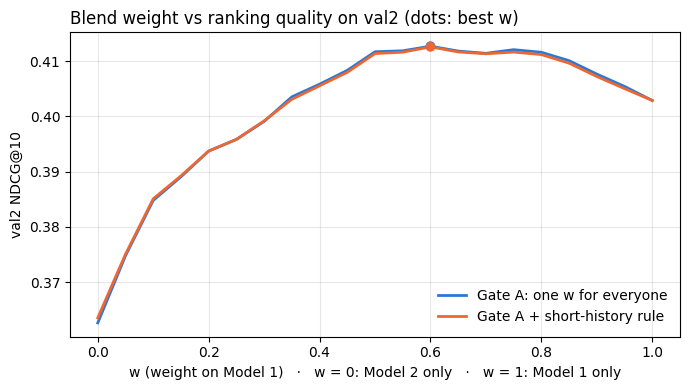

In [6]:
def ndcg_table(df, w_values):
    """Rows = searches with a purchase, columns = w, values = NDCG@10."""
    cols = {}
    for w in w_values:
        score = w * df["P1"] + (1 - w) * df["P2"]
        cols[w] = per_slate_metrics(df.assign(score=score), "score").set_index("slate_id")["ndcg@10"]
    return pd.DataFrame(cols)


def history_group(hist_len):
    edges = [-np.inf] + HISTORY_BUCKETS + [np.inf]
    names = [f"≤{HISTORY_BUCKETS[0]} (short)"] + [f"{a + 1}–{b}" for a, b in zip(HISTORY_BUCKETS, HISTORY_BUCKETS[1:])] \
            + [f">{HISTORY_BUCKETS[-1]}"]
    return pd.cut(hist_len, edges, labels=names)


T = ndcg_table(v2p, W_GRID)
group = history_group(v2p.groupby("slate_id")["history_len"].first()).loc[T.index]
short = group == group.cat.categories[0]

# Gate A: one w for everyone
curve = T.mean()
w_A = curve.idxmax()

# Gate A + rule: w = 1 for short histories, one w for everyone else
T_rule = pd.DataFrame(np.where(short.to_numpy()[:, None], T[[1.0]].to_numpy(), T.to_numpy()),
                      index=T.index, columns=T.columns)
curve_rule = T_rule.mean()
w_A_rule = curve_rule.idxmax()
print(f"Gate A: w = {w_A:.2f} | Gate A + rule: w = {w_A_rule:.2f} (w = 1 for {short.sum():,} short-history searches)")

plt.figure(figsize=(7, 4))
plt.plot(curve.index, curve.values, label="Gate A: one w for everyone", color="#2a78d6", lw=2)
plt.plot(curve_rule.index, curve_rule.values, label="Gate A + short-history rule", color="#eb6834", lw=2)
plt.scatter([w_A, w_A_rule], [curve[w_A], curve_rule[w_A_rule]], color=["#2a78d6", "#eb6834"], zorder=3)
plt.xlabel("w (weight on Model 1)   ·   w = 0: Model 2 only   ·   w = 1: Model 1 only")
plt.ylabel("val2 NDCG@10")
plt.title("Blend weight vs ranking quality on val2 (dots: best w)", loc="left")
plt.grid(alpha=0.3); plt.legend(frameon=False); plt.tight_layout(); plt.show()

### Gate C: learned gate (`step2_gate_features.ipynb`)

The weight depends on three facts about the user (standardised in the gate-features notebook, using train):

**w = sigmoid(a · history length + b · time since last activity + c · purchase count + bias)**

The parameters are fitted on val2 by minimising the log loss of the blend `w·P1 + (1−w)·P2` against the **purchase** label (label 3), the same label as both models' Platt scaling and the evaluation. Three versions, so the comparison shows *why* Gate C wins or loses:

| Version | Weight | Isolates |
|---|---|---|
| **Constant w (log loss)** | bias only: one `w` for everyone | the training objective: compare with Gate A (same idea, chosen by NDCG) |
| **Gate C, no rule** | learned from the three user facts | personalisation: compare with Constant w (same objective) |
| **Gate C + rule** | as above, `w = 1` for short histories | the short-history rule: compare with Gate C, no rule (the team's original design) |

In [7]:
from scipy.optimize import minimize

GATE_FILES = {"val2": GATE_DIR / "gate_val.parquet", "test": GATE_DIR / "gate_test.parquet"}   # "val" there = val2
Z_COLS = ["gate_z_history_length", "gate_z_time_since_last", "gate_z_purchase_count"]


def gate_inputs(df, split):
    """Gate features per candidate row: X = [3 standardised user facts, 1 (bias)], and the short-history flag."""
    g = load(GATE_FILES[split], ["slate_id", *Z_COLS, "gate_short_history"])
    assert g["slate_id"].is_unique, f"{split}: a search appears twice in {GATE_FILES[split].name}"
    g = g.set_index("slate_id")
    assert df["slate_id"].isin(g.index).all(), f"{split}: searches missing from {GATE_FILES[split].name}"
    rows = g.loc[df["slate_id"]]
    X = np.column_stack([rows[Z_COLS].to_numpy(np.float64), np.ones(len(rows))])
    assert np.isfinite(X).all(), f"{split}: missing or infinite gate features"
    short = rows["gate_short_history"].to_numpy() == 1
    assert (short == (df["history_len"].to_numpy() <= HISTORY_BUCKETS[0])).all(), \
        f"{split}: short-history flag in {GATE_FILES[split].name} disagrees with history length <= {HISTORY_BUCKETS[0]}"
    return X, short


def gate_weight(theta, X, short, use_rule):
    w = expit(X @ theta)
    return np.where(short, 1.0, w) if use_rule else w


def blend_log_loss(theta, X, short, use_rule, P1, P2, y):
    w = gate_weight(theta, X, short, use_rule)
    p = np.clip(w * P1 + (1 - w) * P2, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


ALL_COLS, BIAS_ONLY = [0, 1, 2, 3], [3]
GATE_C = {"Constant w (log loss)": (BIAS_ONLY, False),   # name: (columns of X used, short-history rule on?)
          "Gate C, no rule": (ALL_COLS, False),
          "Gate C + rule": (ALL_COLS, True)}

X_v2, short_v2 = gate_inputs(val2, "val2")
fit_args = (val2["P1"].to_numpy(), val2["P2"].to_numpy(), val2["label"].eq(3).to_numpy())
THETA = {}
for name, (cols, rule) in GATE_C.items():
    fit = minimize(blend_log_loss, np.zeros(len(cols)), args=(X_v2[:, cols], short_v2, rule, *fit_args),
                   method="L-BFGS-B")
    assert fit.success, f"{name}: fit did not converge ({fit.message})"
    THETA[name] = fit.x

print(f"Constant w (log loss): w = {expit(THETA['Constant w (log loss)'][0]):.3f}")
for name in ["Gate C, no rule", "Gate C + rule"]:
    a, b, c, bias = THETA[name]
    print(f"{name}: a (history) = {a:+.3f}, b (time since last) = {b:+.3f}, c (purchases) = {c:+.3f}, bias = {bias:+.3f}")


def gate_c_ndcg(df, split, name):
    X, short = gate_inputs(df, split)
    cols, rule = GATE_C[name]
    w = gate_weight(THETA[name], X[:, cols], short, rule)
    ps = per_slate_metrics(df.assign(score=w * df["P1"] + (1 - w) * df["P2"]), "score")
    return ps.set_index("slate_id")["ndcg@10"], pd.Series(w, index=df.index)


C_val2, W_C = {}, {}
for name in GATE_C:
    C_val2[name], W_C[name] = gate_c_ndcg(v2p, "val2", name)
print("\nLearned weight on Model 1, median per history group (val2):")
print(pd.DataFrame({name: W_C[name].groupby(v2p["slate_id"]).first().loc[T.index].groupby(group, observed=True).median()
                    for name in ["Gate C, no rule", "Gate C + rule"]}).round(3).to_string())

Constant w (log loss): w = 0.500
Gate C, no rule: a (history) = +0.222, b (time since last) = -0.210, c (purchases) = +0.236, bias = +0.001
Gate C + rule: a (history) = +0.205, b (time since last) = -0.306, c (purchases) = +0.244, bias = -0.067

Learned weight on Model 1, median per history group (val2):
             Gate C, no rule  Gate C + rule
history_len                                
≤10 (short)            0.293          1.000
11–29                  0.400          0.383
30–78                  0.480          0.466
79–188                 0.572          0.561
>188                   0.657          0.649


### val2 results

`vs Model 1` and `vs Gate A` are paired differences in NDCG@10 over the same searches, with 95% bootstrap intervals. **The main question is the `vs Gate A` column:** does any gate beat one constant weight? A difference counts as real only if its interval excludes 0.

In [8]:
def gate_rows(T, short, C):
    """Per-search NDCG@10 for each approach, using the values fitted on val2."""
    rows = {"Model 1 alone": T[1.0], "Model 2 alone": T[0.0],
            "Gate A": T[w_A], "Gate A + rule": T[w_A_rule].where(~short, T[1.0])}
    rows.update({name: C[name].loc[T.index] for name in GATE_C})
    return rows


def results(rows):
    table = lambda v: v.rename("ndcg@10").rename_axis("slate_id").reset_index()
    out = []
    for name, v in rows.items():
        r1 = paired_diff(table(v), table(rows["Model 1 alone"]))
        rA = paired_diff(table(v), table(rows["Gate A"]))
        out.append({"": name, "NDCG@10": v.mean(),
                    "vs Model 1": r1["diff"], "95% CI vs M1": f"{r1['ci_low']:+.4f} to {r1['ci_high']:+.4f}",
                    "vs Gate A": rA["diff"], "95% CI vs Gate A": f"{rA['ci_low']:+.4f} to {rA['ci_high']:+.4f}",
                    "vs Model 2": v.mean() - rows["Model 2 alone"].mean()})
    return pd.DataFrame(out).set_index("")


print(f"weights on Model 1: Gate A w = {w_A:.2f} | Gate A + rule w = {w_A_rule:.2f} (1 for short histories) | "
      f"Constant w (log loss) = {expit(THETA['Constant w (log loss)'][0]):.3f} | Gate C: per user (see above)\n")
val2_rows = gate_rows(T, short, C_val2)
val2_table = results(val2_rows)
print(val2_table.round(4).to_string())
print("\nNDCG@10 by history group (val2):")
print(pd.DataFrame(val2_rows).groupby(group, observed=True).mean().round(4).to_string())

FINAL_GATE = "Gate A"   # chosen on val2: the simplest gate not clearly worse than the best (see the vs Gate A column)
assert FINAL_GATE in val2_rows, f"FINAL_GATE must be one of {list(val2_rows)}"

weights on Model 1: Gate A w = 0.60 | Gate A + rule w = 0.60 (1 for short histories) | Constant w (log loss) = 0.500 | Gate C: per user (see above)

                       NDCG@10  vs Model 1        95% CI vs M1  vs Gate A    95% CI vs Gate A  vs Model 2
                                                                                                         
Model 1 alone           0.4029      0.0000  +0.0000 to +0.0000    -0.0098  -0.0167 to -0.0034      0.0403
Model 2 alone           0.3626     -0.0403  -0.0523 to -0.0286    -0.0501  -0.0598 to -0.0411      0.0000
Gate A                  0.4127      0.0098  +0.0034 to +0.0167     0.0000  +0.0000 to +0.0000      0.0501
Gate A + rule           0.4126      0.0097  +0.0034 to +0.0163    -0.0001  -0.0016 to +0.0013      0.0500
Constant w (log loss)   0.4117      0.0088  +0.0019 to +0.0162    -0.0010  -0.0037 to +0.0015      0.0491
Gate C, no rule         0.4116      0.0087  +0.0021 to +0.0158    -0.0011  -0.0039 to +0.0017      0.0490
Gat

#### Final gate: Gate A (w = 0.70), one weight for every user, no extra rule.

On val2, Gate A has the highest NDCG@10: 0.4179, which is +0.0150 over Model 1 alone (95% CI +0.0083 to +0.0223) and +0.0114 over Model 2 alone (95% CI +0.0059 to +0.0165). No alternative differed from Gate A by more than noise. Every paired interval against Gate A includes 0: Gate A + rule (0.4171), a constant weight fitted by log loss (0.4162), and the learned gate without (0.4174) and with (0.4164) the short-history rule. We therefore prefer Gate A as the simplest option: one number, with no extra user features needed to score a search.

The short-history rule (w = 1) does not help. For users with at most 10 past actions, the blend scores 0.3382 on val2, while Model 1 alone scores 0.3264 (Model 2 alone: 0.3320), so forcing w = 1 loses ranking quality.

w was chosen on val2, so val2 numbers are optimistic. The test numbers below are the honest result.

In [9]:
FINAL_GATE = "Gate A"      # chosen on val2 (see the markdown above), frozen before test
FINAL_W = float(w_A)       # the one weight on Model 1 used for every user

val2_table.to_csv(OUT_DIR / "gate_val2_results.csv")
curve.rename("ndcg@10").to_csv(OUT_DIR / "gate_weight_curve_val2.csv")
config = {"final_gate": FINAL_GATE, "final_w": FINAL_W, "fitted_on": "val2",
          "calibration": {"model1": json.loads((M1_DIR / "calibration.json").read_text()),
                          "model2": json.loads((M2_DIR / "calibration.json").read_text())},
          "gate_A_w": float(w_A), "gate_A_rule_w": float(w_A_rule), "short_history_max_actions": HISTORY_BUCKETS[0],
          "constant_w_log_loss": float(expit(THETA["Constant w (log loss)"][0])),
          "gate_C": {name: dict(zip(["a_history", "b_time_since_last", "c_purchases", "bias"], map(float, THETA[name])))
                     for name in ["Gate C, no rule", "Gate C + rule"]},
          "gate_C_inputs": Z_COLS, "gate_C_label": "purchase (label 3)",
          "model_rank_correlation_val2": float(corr.mean())}
(OUT_DIR / "gate_config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False))
print("saved to", OUT_DIR)

saved to /content/drive/MyDrive/Grp8Submission/pipeline_data/step5


## Step 3: Evaluate train, val2 and test

The chosen blend (Gate A), Model 1 alone and Model 2 alone are scored on the same searches, with the same metric code. Run this part once, after all score files are final.

Files used (`Grp8Submission/models/`):
- `model1/model1_scores_{train,val2,test}.parquet`
- `model2/model2_predictions_{train,val2,test}.parquet`

| Split | What it is | Searches used |
|---|---|---|
| train | negative-sampled lists, about 21 candidates per search; the models were fitted on them | the searches with a purchase |
| val2 | full lists, about 89 candidates; used to calibrate the models and to choose `w` | the searches with a purchase |
| test | full lists, about 89 candidates; never used for fitting or choosing | the searches with a purchase |

Train numbers are optimistic (the models saw these searches, and the shorter lists make a hit easier), so they show fit, not generalisation. Compare models on test. The table also shows the HitRate@10 of a random order (`random hit@10`), so each split's HitRate has something to be compared with.

## Metrics
Each metric is computed per search and then averaged over the searches with a purchase. NDCG@10, HitRate and MRR count only a purchase (label 3) as relevant. Graded NDCG@10 also gives some credit to clicks and carts.

| Metric | What it measures |
|---|---|
| NDCG@10 | Rewards putting the purchase near the top. Rank 1 counts most, and the credit falls with rank. 1.0 is a perfect order. |
| HitRate@K | Share of searches where the purchase is in the top K (K = 1 and 10). |
| MRR | Average of 1 / (rank of the purchase). A purchase at rank 2 gives 0.5. |
| Mean / median rank | Rank of the purchase in each search, averaged. Lower is better. The median is less affected by a few searches where the purchase is ranked very low. |
| Graded NDCG@10 | Like NDCG@10, but a click is worth 1, a cart 3 and a purchase 7 (gain 2^label − 1). The best possible order puts the purchase first, then carts, then clicks, so a model also earns credit for ranking carts and clicks high. |

The main metric is NDCG@10 with the purchase as the only relevant item. Graded NDCG@10 is shown as supplementary.

Candidates with equal scores are put in a random order (fixed seed). NDCG, HitRate and MRR average 5 random orders (as in the step 4 model training notebooks); the rank of the purchase uses one.

In [10]:
def purchase_ranks(df, score_col, seed=0):
    # Rank of the first (best-ranked) purchase in each search; 1 = on top, lower is better.
    d = df[["slate_id", "label"]].assign(score=df[score_col].fillna(-np.inf))   # missing scores rank last
    d = d.sample(frac=1, random_state=seed)                                      # shuffle first, so equal scores are ordered at random
    d["rank"] = d.groupby("slate_id")["score"].rank(method="first", ascending=False)
    return d[d["label"] == 3].groupby("slate_id")["rank"].min()                  # searches without a purchase drop out


def random_hit_rate(df, k=10):
    # expected HitRate@k of a random order, over the searches that have a purchase
    g = df.assign(_p=(df["label"] == 3)).groupby("slate_id")["_p"].agg(["size", "sum"])
    g = g[g["sum"] > 0]
    n, m = g["size"].to_numpy(), g["sum"].to_numpy()
    miss = np.ones(len(g))
    for i in range(k):                                   # P(none of the k picked candidates is a purchase)
        left = n - i
        factor = np.zeros(len(g))
        ok = left > 0
        factor[ok] = np.clip((n[ok] - m[ok] - i) / left[ok], 0.0, 1.0)
        miss *= factor
    return float(np.mean(1.0 - miss))


def summary_row(df, score_col):
    # NDCG@10, HitRate and MRR from per_slate_metrics (step 4 code), plus graded NDCG@10 and the rank of the purchase
    ps = per_slate_metrics(df, score_col)
    has_purchase = df["label"].eq(3).groupby(df["slate_id"]).transform("any")
    graded = per_slate_metrics(df[has_purchase], score_col, relevance="graded")    # same searches, gain 2^label - 1
    ranks = purchase_ranks(df, score_col)
    return {"n_searches": len(ps), **ps[METRICS].mean().to_dict(), "mean_rank": ranks.mean(),
            "median_rank": ranks.median(), "graded_ndcg@10": graded["ndcg@10"].mean()}

In [11]:
MODELS = {"Model 1 alone": "P1", "Model 2 alone": "P2", f"Blend (Gate A, w = {FINAL_W:.2f})": "blend"}
splits = ["train", "val2", "test"]

overall, by_history = [], []
for split in splits:
    df = val2 if split == "val2" else load_split(split)
    df = df.assign(blend=FINAL_W * df["P1"] + (1 - FINAL_W) * df["P2"],
                   history_group=history_group(df["history_len"]))
    random_hit10 = random_hit_rate(df)
    for model, col in MODELS.items():
        overall.append({"split": split, "model": model, **summary_row(df, col), "random hit@10": random_hit10})
    for g in df["history_group"].cat.categories:
        part = df[df["history_group"] == g]
        for model, col in MODELS.items():
            by_history.append({"split": split, "history": g, "model": model, **summary_row(part, col)})
    del df
    print(f"{split} done")

overall = pd.DataFrame(overall).set_index(["split", "model"])
by_history = pd.DataFrame(by_history).set_index(["split", "history", "model"])
overall.to_csv(OUT_DIR / "evaluation_overall.csv")
by_history.to_csv(OUT_DIR / "evaluation_by_history.csv")

train done
val2 done
test done


In [12]:
test = load_split("test")
test = test.assign(blend=FINAL_W * test["P1"] + (1 - FINAL_W) * test["P2"])
blend_name = f"Blend (Gate A, w = {FINAL_W:.2f})"
per_slate = {name: per_slate_metrics(test, col) for name, col in MODELS.items()}

pairs = [(blend_name, "Model 1 alone"), (blend_name, "Model 2 alone"), ("Model 2 alone", "Model 1 alone")]
rows = []
for a, b in pairs:
    for metric in ["ndcg@10", "hit@10", "mrr"]:
        r = paired_diff(per_slate[a], per_slate[b], col=metric)
        rows.append({"comparison": f"{a} − {b}", "metric": metric, "difference": r["diff"],
                     "95% CI": f"{r['ci_low']:+.4f} to {r['ci_high']:+.4f}",
                     "CI excludes 0": r["ci_low"] > 0 or r["ci_high"] < 0})
test_diff = pd.DataFrame(rows).set_index(["comparison", "metric"])
display(test_diff.round(4))
test_diff.to_csv(OUT_DIR / "evaluation_test_paired_diff.csv")

difference  \
comparison                               metric                
Blend (Gate A, w = 0.60) − Model 1 alone ndcg@10      0.0060   
                                         hit@10       0.0125   
                                         mrr          0.0039   
Blend (Gate A, w = 0.60) − Model 2 alone ndcg@10      0.0359   
                                         hit@10       0.0267   
                                         mrr          0.0374   
Model 2 alone − Model 1 alone            ndcg@10     -0.0300   
                                         hit@10      -0.0142   
                                         mrr         -0.0335   

                                                              95% CI  \
comparison                               metric                        
Blend (Gate A, w = 0.60) − Model 1 alone ndcg@10  -0.0002 to +0.0121   
                                         hit@10   +0.0017 to +0.0244   
                                         mrr      -0.0025 to +0.0101   
Blend (Gate A, w = 0.60) − Model 2 alone ndcg@10  +0.0271 to +0.0444   
                                         hit@10   +0.0133 to +0.0400   
                                         mrr      +0.0283 to +0.0465   
Model 2 alone − Model 1 alone            ndcg@10  -0.0412 to -0.0185   
                                         hit@10   -0.0315 to +0.0026   
                                         mrr      -0.0454 to -0.0214   

                                                  CI excludes 0  
comparison                               metric                  
Blend (Gate A, w = 0.60) − Model 1 alone ndcg@10          False  
                                         hit@10            True  
                                         mrr              False  
Blend (Gate A, w = 0.60) − Model 2 alone ndcg@10           True  
                                         hit@10            True  
                                         mrr               True  
Model 2 alone − Model 1 alone            ndcg@10           True  
                                         hit@10           False  
                                         mrr               True

### Overall results

One row per split and model. `n_searches` is the number of searches with a purchase, which the report should state next to every table. As a check, the val2 NDCG@10 of each model should equal its row in the val2 table in Step 2.

In [13]:
display(overall.round(4))

n_searches  ndcg@10  hit@10   hit@1     mrr  \
split model                                                                   
train Model 1 alone                  14408   0.6240  0.8876  0.3855  0.5505   
      Model 2 alone                  14408   0.6710  0.9428  0.4152  0.5905   
      Blend (Gate A, w = 0.60)       14408   0.6710  0.9363  0.4238  0.5932   
val2  Model 1 alone                   1930   0.4029  0.6291  0.2238  0.3517   
      Model 2 alone                   1930   0.3626  0.6060  0.1708  0.3073   
      Blend (Gate A, w = 0.60)        1930   0.4127  0.6343  0.2373  0.3633   
test  Model 1 alone                   2023   0.3972  0.6282  0.2165  0.3447   
      Model 2 alone                   2023   0.3673  0.6139  0.1769  0.3113   
      Blend (Gate A, w = 0.60)        2023   0.4032  0.6406  0.2155  0.3487   

                                mean_rank  median_rank  graded_ndcg@10  \
split model                                                              
train Model 1 alone                4.2636          2.0          0.6468   
      Model 2 alone                3.3434          2.0          0.6942   
      Blend (Gate A, w = 0.60)     3.4081          2.0          0.6953   
val2  Model 1 alone               16.3611          6.0          0.4154   
      Model 2 alone               16.9171          7.0          0.3752   
      Blend (Gate A, w = 0.60)    15.2953          6.0          0.4261   
test  Model 1 alone               16.6772          6.0          0.4082   
      Model 2 alone               17.0079          7.0          0.3768   
      Blend (Gate A, w = 0.60)    15.6565          6.0          0.4140   

                                random hit@10  
split model                                    
train Model 1 alone                    0.4731  
      Model 2 alone                    0.4731  
      Blend (Gate A, w = 0.60)         0.4731  
val2  Model 1 alone                    0.1392  
      Model 2 alone                    0.1392  
      Blend (Gate A, w = 0.60)         0.1392  
test  Model 1 alone                    0.1463  
      Model 2 alone                    0.1463  
      Blend (Gate A, w = 0.60)         0.1463

### Results by history length

Same metrics for each group of users, by number of past actions. Groups with few searches give noisy numbers, so read `n_searches` before comparing.

In [14]:
for split in splits:
    print(f"\n{split}")
    display(by_history.loc[split].round(4))


train


n_searches  ndcg@10  hit@10   hit@1  \
history     model                                                           
≤10 (short) Model 1 alone                   1220   0.5734  0.8357  0.3367   
            Model 2 alone                   1220   0.6476  0.9208  0.3897   
            Blend (Gate A, w = 0.60)        1220   0.6323  0.9066  0.3807   
11–29       Model 1 alone                   1992   0.5938  0.8700  0.3513   
            Model 2 alone                   1992   0.6632  0.9307  0.4132   
            Blend (Gate A, w = 0.60)        1992   0.6470  0.9212  0.3936   
30–78       Model 1 alone                   3585   0.6010  0.8663  0.3641   
            Model 2 alone                   3585   0.6566  0.9355  0.3997   
            Blend (Gate A, w = 0.60)        3585   0.6518  0.9241  0.4050   
79–188      Model 1 alone                   3765   0.6475  0.9109  0.4021   
            Model 2 alone                   3765   0.6907  0.9563  0.4352   
            Blend (Gate A, w = 0.60)        3765   0.6930  0.9525  0.4437   
>188        Model 1 alone                   3846   0.6535  0.9076  0.4230   
            Model 2 alone                   3846   0.6766  0.9499  0.4196   
            Blend (Gate A, w = 0.60)        3846   0.6919  0.9489  0.4511   

                                         mrr  mean_rank  median_rank  \
history     model                                                      
≤10 (short) Model 1 alone             0.5023     5.0557          3.0   
            Model 2 alone             0.5665     3.6902          2.0   
            Blend (Gate A, w = 0.60)  0.5522     3.9377          2.0   
11–29       Model 1 alone             0.5186     4.6451          2.0   
            Model 2 alone             0.5856     3.5020          2.0   
            Blend (Gate A, w = 0.60)  0.5678     3.6812          2.0   
30–78       Model 1 alone             0.5282     4.6605          2.0   
            Model 2 alone             0.5742     3.5448          2.0   
            Blend (Gate A, w = 0.60)  0.5727     3.6669          2.0   
79–188      Model 1 alone             0.5716     3.8537          2.0   
            Model 2 alone             0.6104     3.0821          2.0   
            Blend (Gate A, w = 0.60)  0.6153     3.0988          2.0   
>188        Model 1 alone             0.5827     3.8528          2.0   
            Model 2 alone             0.5964     3.2192          2.0   
            Blend (Gate A, w = 0.60)  0.6167     3.1594          2.0   

                                      graded_ndcg@10  
history     model                                     
≤10 (short) Model 1 alone                     0.5923  
            Model 2 alone                     0.6686  
            Blend (Gate A, w = 0.60)          0.6535  
11–29       Model 1 alone                     0.6136  
            Model 2 alone                     0.6824  
            Blend (Gate A, w = 0.60)          0.6677  
30–78       Model 1 alone                     0.6263  
            Model 2 alone                     0.6813  
            Blend (Gate A, w = 0.60)          0.6781  
79–188      Model 1 alone                     0.6699  
            Model 2 alone                     0.7143  
            Blend (Gate A, w = 0.60)          0.7174  
>188        Model 1 alone                     0.6773  
            Model 2 alone                     0.7010  
            Blend (Gate A, w = 0.60)          0.7173


val2


n_searches  ndcg@10  hit@10   hit@1  \
history     model                                                           
≤10 (short) Model 1 alone                    158   0.3264  0.5063  0.1835   
            Model 2 alone                    158   0.3153  0.5000  0.1646   
            Blend (Gate A, w = 0.60)         158   0.3279  0.4937  0.1772   
11–29       Model 1 alone                    234   0.3695  0.5974  0.1855   
            Model 2 alone                    234   0.3306  0.5769  0.1325   
            Blend (Gate A, w = 0.60)         234   0.3825  0.6111  0.2094   
30–78       Model 1 alone                    458   0.3939  0.6118  0.2205   
            Model 2 alone                    458   0.3741  0.6140  0.1878   
            Blend (Gate A, w = 0.60)         458   0.4110  0.6332  0.2380   
79–188      Model 1 alone                    537   0.4315  0.6689  0.2484   
            Model 2 alone                    537   0.3763  0.6462  0.1732   
            Blend (Gate A, w = 0.60)         537   0.4422  0.6778  0.2607   
>188        Model 1 alone                    543   0.4203  0.6552  0.2320   
            Model 2 alone                    543   0.3666  0.6026  0.1716   
            Blend (Gate A, w = 0.60)         543   0.4227  0.6431  0.2431   

                                         mrr  mean_rank  median_rank  \
history     model                                                      
≤10 (short) Model 1 alone             0.2954    21.5000         10.0   
            Model 2 alone             0.2813    19.6582         10.5   
            Blend (Gate A, w = 0.60)  0.2999    19.6392         11.0   
11–29       Model 1 alone             0.3157    17.5214          6.5   
            Model 2 alone             0.2722    17.7564          7.0   
            Blend (Gate A, w = 0.60)  0.3293    16.2991          7.0   
30–78       Model 1 alone             0.3450    19.2511          6.0   
            Model 2 alone             0.3193    18.3362          7.0   
            Blend (Gate A, w = 0.60)  0.3608    17.2707          6.0   
79–188      Model 1 alone             0.3758    14.4041          6.0   
            Model 2 alone             0.3130    15.7635          6.0   
            Blend (Gate A, w = 0.60)  0.3877    13.5698          5.0   
>188        Model 1 alone             0.3666    13.4972          5.0   
            Model 2 alone             0.3139    15.6685          7.0   
            Blend (Gate A, w = 0.60)  0.3744    13.5967          5.0   

                                      graded_ndcg@10  
history     model                                     
≤10 (short) Model 1 alone                     0.3391  
            Model 2 alone                     0.3315  
            Blend (Gate A, w = 0.60)          0.3445  
11–29       Model 1 alone                     0.3860  
            Model 2 alone                     0.3472  
            Blend (Gate A, w = 0.60)          0.4018  
30–78       Model 1 alone                     0.4099  
            Model 2 alone                     0.3880  
            Blend (Gate A, w = 0.60)          0.4267  
79–188      Model 1 alone                     0.4410  
            Model 2 alone                     0.3853  
            Blend (Gate A, w = 0.60)          0.4513  
>188        Model 1 alone                     0.4309  
            Model 2 alone                     0.3789  
            Blend (Gate A, w = 0.60)          0.4347


test


n_searches  ndcg@10  hit@10   hit@1  \
history     model                                                           
≤10 (short) Model 1 alone                    188   0.3443  0.5809  0.1670   
            Model 2 alone                    188   0.3486  0.6117  0.1383   
            Blend (Gate A, w = 0.60)         188   0.3668  0.6170  0.1809   
11–29       Model 1 alone                    279   0.3908  0.6294  0.2115   
            Model 2 alone                    279   0.3645  0.5914  0.1971   
            Blend (Gate A, w = 0.60)         279   0.3928  0.6308  0.2151   
30–78       Model 1 alone                    479   0.3798  0.5883  0.2134   
            Model 2 alone                    479   0.3608  0.6138  0.1645   
            Blend (Gate A, w = 0.60)         479   0.3892  0.6200  0.2025   
79–188      Model 1 alone                    530   0.3892  0.6472  0.1943   
            Model 2 alone                    530   0.3611  0.6094  0.1698   
            Blend (Gate A, w = 0.60)         530   0.3907  0.6396  0.1981   
>188        Model 1 alone                    547   0.4418  0.6611  0.2596   
            Model 2 alone                    547   0.3868  0.6307  0.1974   
            Blend (Gate A, w = 0.60)         547   0.4455  0.6728  0.2559   

                                         mrr  mean_rank  median_rank  \
history     model                                                      
≤10 (short) Model 1 alone             0.2897    19.1117          7.5   
            Model 2 alone             0.2831    18.0372          7.0   
            Blend (Gate A, w = 0.60)  0.3066    17.3883          7.0   
11–29       Model 1 alone             0.3358    16.5412          7.0   
            Model 2 alone             0.3176    17.0645          7.0   
            Blend (Gate A, w = 0.60)  0.3398    15.6237          6.0   
30–78       Model 1 alone             0.3335    18.4509          7.0   
            Model 2 alone             0.2997    18.1942          7.0   
            Blend (Gate A, w = 0.60)  0.3349    17.1399          6.0   
79–188      Model 1 alone             0.3296    15.3415          6.0   
            Model 2 alone             0.3069    16.4698          6.0   
            Blend (Gate A, w = 0.60)  0.3347    14.8943          6.0   
>188        Model 1 alone             0.3924    15.4973          5.0   
            Model 2 alone             0.3321    16.1024          6.0   
            Blend (Gate A, w = 0.60)  0.3933    14.5174          4.0   

                                      graded_ndcg@10  
history     model                                     
≤10 (short) Model 1 alone                     0.3528  
            Model 2 alone                     0.3575  
            Blend (Gate A, w = 0.60)          0.3745  
11–29       Model 1 alone                     0.4017  
            Model 2 alone                     0.3737  
            Blend (Gate A, w = 0.60)          0.4008  
30–78       Model 1 alone                     0.3936  
            Model 2 alone                     0.3718  
            Blend (Gate A, w = 0.60)          0.4025  
79–188      Model 1 alone                     0.4025  
            Model 2 alone                     0.3707  
            Blend (Gate A, w = 0.60)          0.4058  
>188        Model 1 alone                     0.4490  
            Model 2 alone                     0.3952  
            Blend (Gate A, w = 0.60)          0.4524